# Week 12 In-Class Demo 1
## Multiple Regression and Regularization with Health-Service Costs

### Business question
Using the **same synthetic health dataset from Weeks 11–12**, can a health-services organization estimate `avg_visit_cost` from patient and service characteristics?

This changes the problem from classification to **regression** because the target is a number measured in dollars. The goal is not clinical prediction. It is to practise how a business analyst builds and compares understandable regression workflows.

## Learning objectives
By the end of this in-class demonstration, students should be able to:

1. **Frame a business problem as regression** by identifying a numerical target, appropriate predictors, and the point in time when a prediction is needed.
2. **Explain multiple linear regression in plain language** as a model that combines several predictors to estimate one numerical outcome.
3. **Build a leakage-safe regression workflow** using `ColumnTransformer` and `Pipeline` for missing-value imputation, categorical encoding, numerical scaling, and model fitting.
4. **Interpret MAE, RMSE, and R² in business terms**, including why R² should not be described as classification accuracy.
5. **Explain the purpose of regularization** as a way to constrain model complexity and coefficient size.
6. **Distinguish Ridge, Lasso, and ElasticNet** based on how each method penalizes coefficients.
7. **Compare regression models using unseen test data** and determine whether a numerical improvement is practically meaningful.
8. **Interpret coefficients cautiously** as fitted associations rather than proof of causal relationships.
9. **Communicate a model recommendation to a non-technical manager** using evidence, limitations, and operational trade-offs.
10. **Transfer the workflow to the Term Project Salary-regression task** while avoiding target leakage and unsupported claims.

> **Student success indicator:** A student should be able to explain not only which model produced the lowest error, but also whether the difference is meaningful enough to influence a business decision.

## Bridge from earlier regression
You have already seen simple linear regression. Multiple regression keeps the same basic idea but uses many predictors at once.

Week 12 then introduces **regularization**. Ridge, Lasso, and ElasticNet modify linear regression so large or unnecessary coefficients are discouraged. This can help when predictors overlap in information or when the model becomes overly sensitive to the training sample.

For BBA students, think of regularization as a **complexity budget**: the model can still use many predictors, but it pays a penalty for relying too aggressively on them.

## Week 12 resources
- [Course Delivery Plan](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=42c15f8c0a8a487a9c578486-56)
- [Lecture 21–22 recording](https://nait.video.yuja.com/V/Video?v=1347378&node=7565673&a=140557614)
- [Lecture 21–22 presentation](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551463)
- [Lecture 21 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture21_Multiple_Regression.ipynb)
- [Lecture 21–22 student workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture21_22_workbook.ipynb)
- [Workbook solution](https://colab.research.google.com/drive/1OdWqGU-jSto8-I49bnP2NOCQAwPfYdZx?usp=sharing)
- [O’Reilly: *Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)
  - **Chapter 9: More Regression Methods**
  - **Chapter 11: Tuning Hyperparameters and Pipelines**
- [Machine Learning Assignment 2](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551201)
- [Term Project](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551222)

## What to focus on
- regression predicts a numeric outcome;
- MAE and RMSE are errors expressed in dollars;
- R² describes the share of target variation explained by the model, not dollars;
- correlated predictors can make individual coefficients unstable;
- Ridge shrinks coefficients;
- Lasso can shrink some coefficients all the way to zero;
- ElasticNet combines Ridge- and Lasso-style penalties;
- scaling is especially important before comparing regularized coefficients.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE=42

## Regression vocabulary for BBA students

Before we start coding, keep these four ideas separate. These terms appear throughout the notebook.

### 1. Target

The **target** is the outcome the organization wants the model to estimate.

**In this demonstration:** `avg_visit_cost`

---

### 2. Predictor

A **predictor** is a piece of information used to help estimate the target.

**Examples in this demonstration:**

- `age`
- `region`
- `prior_admissions`
- `bmi`
- `chronic_conditions`

---

### 3. Prediction

A **prediction** is the value produced by the fitted model for one record.

**Example:**

The model estimates that a patient's average visit cost will be **CAD 820**.

---

### 4. Residual or prediction error

A **residual** is the difference between the actual value and the model's prediction.

The residual is commonly calculated as:

`residual = actual value - predicted value`

**Example:**

- Actual visit cost: **CAD 900**
- Predicted visit cost: **CAD 820**
- Residual: **CAD 80**

The positive residual means that the model underestimated the actual cost by **CAD 80**.

---

### Why the size of the error matters

Regression is different from classification because the prediction is a **number**, not a category such as Yes or No.

Consider the following two predictions:

#### Prediction A

- Actual visit cost: **CAD 900**
- Predicted visit cost: **CAD 890**
- Error magnitude: **CAD 10**

#### Prediction B

- Actual visit cost: **CAD 900**
- Predicted visit cost: **CAD 600**
- Error magnitude: **CAD 300**

Both predictions miss the exact value. However, Prediction A is much closer to the actual cost.

Regression metrics such as **Mean Absolute Error (MAE)** and **Root Mean Squared Error (RMSE)** summarize the size of prediction errors across many records.

> **BBA takeaway:** In regression, do not ask only, “Was the prediction exactly correct?” Instead, ask, **“How large was the miss, and is that size acceptable for the business decision?”**

> **Sign convention note:** A residual can be positive or negative because it is calculated as `actual value - predicted value`. MAE and RMSE focus on the size of prediction errors, so positive and negative errors do not cancel each other out.

## Common mistakes to avoid
- Treating R² as classification accuracy.
- Assuming lower training error means better future performance.
- Claiming a coefficient proves causation.
- Comparing regularized coefficients before consistent scaling.
- Assuming Lasso-selected zero means a feature has no business value.
- Choosing the model with the smallest metric difference without asking whether that difference is practically meaningful.

## 1. Reuse the same health dataset
We repeat the documented cleaning rules so this notebook is self-contained. The business target changes, but the underlying data source does not.

The target will be `avg_visit_cost`. Rows without a valid target cannot teach a supervised regression model what cost should have been, so those target-missing rows are excluded from this particular modeling table. Missing predictor values remain and will be handled inside the pipeline.

### Preparing the healthcare data for analysis

Before building a regression model, we first make sure the dataset is **available, complete, and reasonably clean**.

This cell performs four important data-quality steps:

1. **Check the file and required columns**  
   The code confirms that `healthcare_readmission.csv` exists and contains the columns needed for the analysis. This helps catch file or schema problems early instead of producing confusing errors later.

2. **Remove obvious data-quality problems**  
   Duplicate rows are removed, and values such as `NA`, `N/A`, and `unknown` are treated as missing values.

3. **Clean numerical variables**  
   Columns such as `age`, `bmi`, `systolic_bp`, and `avg_visit_cost` are converted to numeric values. Values outside the defined reasonable ranges are changed to missing values rather than being treated as valid observations.

4. **Standardize categorical variables**  
   Different versions of the same category are combined. For example, `F`, `female`, and `Female` are standardized to one consistent value.

#### Why does this matter?

Machine-learning models learn from the data they receive. Inconsistent categories, impossible values, duplicates, and incorrectly formatted numbers can lead to unreliable results.

> **BBA takeaway:** Data cleaning is not just a technical task. It is a **data-quality decision** that affects the reliability of every analysis and model that follows.

At the end of the cell, compare the number of **raw rows** with the number of **clean analytical rows** to see how the cleaning process changed the dataset.

In [11]:
DATA_PATH="healthcare_readmission.csv"
from pathlib import Path

if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. Place the CSV in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
required_columns = {
    "patient_id", "age", "gender", "region", "bmi", "systolic_bp",
    "cholesterol_mmol_l", "hba1c_pct", "smoker_status", "activity_level",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "insurance_type", "appointment_wait_days", "missed_appointments",
    "readmitted_30d"
}
missing_columns = sorted(required_columns - set(df_raw.columns))
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {missing_columns}")
df=df_raw.copy().replace(["","NA","N/A","unknown","Unknown"],np.nan).drop_duplicates().copy()
nums=["age","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","chronic_conditions","prior_admissions","avg_visit_cost","appointment_wait_days","missed_appointments"]
for col in nums: df[col]=pd.to_numeric(df[col],errors="coerce")
ranges={"age":(18,100),"bmi":(12,70),"systolic_bp":(70,250),"cholesterol_mmol_l":(1,15),"hba1c_pct":(3,20),"chronic_conditions":(0,15),"prior_admissions":(0,20),"avg_visit_cost":(0,20000),"appointment_wait_days":(0,365),"missed_appointments":(0,30)}
for col,(lo,hi) in ranges.items(): df.loc[df[col].notna() & ~df[col].between(lo,hi),col]=np.nan
cats=["gender","region","smoker_status","activity_level","insurance_type"]
for col in cats: df[col]=df[col].astype("string").str.strip().str.lower()
maps={"gender":{"f":"Female","female":"Female","m":"Male","male":"Male","nb":"Non-binary","nonbinary":"Non-binary","non-binary":"Non-binary"},"region":{"edmonton":"Edmonton","edm":"Edmonton","calgary":"Calgary","yyc":"Calgary","central alberta":"Central Alberta","northern alberta":"Northern Alberta","north":"Northern Alberta","southern alberta":"Southern Alberta","south":"Southern Alberta"},"smoker_status":{"never":"Never","n":"Never","former":"Former","current":"Current","y":"Current"},"activity_level":{"low":"Low","moderate":"Moderate","high":"High"},"insurance_type":{"employer":"Employer","govt":"Government","government":"Government","private":"Private","un-insured":"Uninsured","uninsured":"Uninsured"}}
for col,m in maps.items():
    df[col]=df[col].map(m).astype(object); df[col]=df[col].where(pd.notna(df[col]),np.nan)
print("Raw rows:",len(df_raw),"Clean analytical rows:",len(df))

Raw rows: 120500 Clean analytical rows: 120000


## Check-in 1: Classification or regression?
We previously predicted `readmitted_30d`. Now we predict `avg_visit_cost`.

<details><summary><strong>Reveal solution</strong></summary>

`readmitted_30d` is classification because the answer is a class, 0 or 1. `avg_visit_cost` is regression because the answer is a continuous dollar amount. Changing the target changes the model family and evaluation metrics, even though the source dataset is the same.

</details>

## Before modeling: define the prediction moment
A model should use only information that would realistically be available when the estimate is needed.

For this classroom example, we assume the listed predictors are available before the organization needs the cost estimate. This is a simplifying teaching assumption. In a real organization, the analyst would document when each field is captured and remove any field created after the outcome.

This is the regression version of the leakage question students encountered in Week 11.

## 2. Prepare predictors and one protected test set
We exclude `patient_id` because it identifies a record. We also exclude `readmitted_30d` so the regression demo stays focused on characteristics available in the selected feature set rather than mixing the earlier classification target into the cost model.

The preprocessing design is familiar from Week 11: numerical imputation/scaling plus categorical imputation/one-hot encoding.

In [15]:
target="avg_visit_cost"
features=["age","gender","region","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","smoker_status","activity_level","chronic_conditions","prior_admissions","insurance_type","appointment_wait_days","missed_appointments"]
model_df=df[features+[target]].copy()
model_df=model_df.dropna(subset=[target])
X=model_df[features]; y=model_df[target]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE)
num=["age","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","chronic_conditions","prior_admissions","appointment_wait_days","missed_appointments"]
cat=["gender","region","smoker_status","activity_level","insurance_type"]
pre=ColumnTransformer([("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),num),("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)])
print("Training rows:",len(X_train),"Test rows:",len(X_test))

Training rows: 93248 Test rows: 23313


## From simple to multiple regression
With one predictor, a linear regression line has one slope. With many predictors, the same idea expands to several coefficients:

`predicted cost = intercept + coefficient₁×feature₁ + coefficient₂×feature₂ + ...`

You do **not** need to solve this equation by hand. The useful business interpretation is that the model combines several pieces of information into one cost estimate.

### Why multiple predictors can help
A single field rarely captures an operational outcome completely. Cost may be associated with several service and patient characteristics at the same time. Multiple regression lets the model account for several signals together.

### Why multiple predictors can also create problems
If predictors contain overlapping information, coefficient estimates can become unstable. That is one motivation for regularization later in this notebook.

## 🎥 Short theory video: Multiple Regression
Run the video cell below before the first multiple-regression model.

**Video:** Multiple Regression, Clearly Explained!!! by StatQuest, approximately **5 minutes 25 seconds**.

### While watching, focus on:
1. How does multiple regression extend a single-predictor regression?
2. What does it mean to estimate one coefficient while holding other predictors constant?
3. Why does association not automatically prove causation?

If embedded playback is blocked, use the fallback link:

[Open the video on YouTube](https://www.youtube.com/watch?v=EkAQAi3a4js)

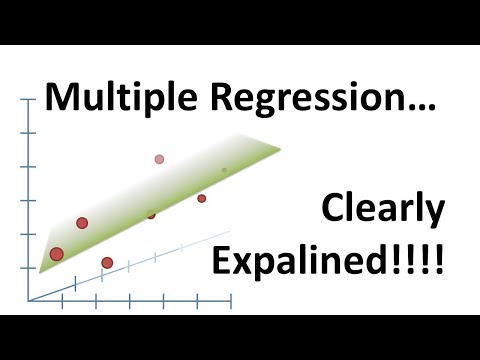

In [18]:
# Embedded YouTube video for Jupyter / Google Colab.
from IPython.display import YouTubeVideo, display

display(YouTubeVideo("EkAQAi3a4js", width=800, height=450))

## Video check-in
Which statement is more accurate?

A. Multiple regression proves how each predictor causes the target to change.  
B. Multiple regression estimates associations between the target and several predictors in one fitted model.

<details><summary><strong>Reveal solution</strong></summary>

**B is more accurate.** The fitted coefficients summarize model associations while other included inputs are held constant. Causal claims require a much stronger research design and assumptions than this observational prediction exercise provides.

</details>

## 3. Start with multiple linear regression
Multiple linear regression estimates one coefficient per transformed predictor. A coefficient represents an expected change in predicted cost when that model input changes, holding the other model inputs constant.

That statement is **associational**, not causal. A positive coefficient does not prove that changing the predictor would cause cost to increase.

In [21]:
linear=Pipeline([("preprocess",pre),("regressor",LinearRegression())])
linear.fit(X_train,y_train)
linear_pred=linear.predict(X_test)

def regression_metrics(name,y_true,y_pred):
    return {"model":name,"MAE":mean_absolute_error(y_true,y_pred),"RMSE":mean_squared_error(y_true,y_pred)**0.5,"R2":r2_score(y_true,y_pred)}

baseline_metrics=regression_metrics("Linear Regression",y_test,linear_pred)
pd.DataFrame([baseline_metrics]).round(3)

,model,MAE,RMSE,R2
0,Linear Regression,263.003,342.79,0.109


### How to review the baseline output
Read the table from left to right:

1. **MAE:** What is the typical absolute dollar miss?
2. **RMSE:** Is the model being penalized more strongly for some large misses?
3. **R²:** How much of the variation in visit cost is explained relative to predicting the mean?

Do not convert R² into a statement such as “the model is 11% accurate.” R² and accuracy are different concepts.

## 4. Read regression metrics in business language
- **MAE** is the average absolute dollar miss. If MAE is $300, predictions are off by about $300 on average, ignoring direction.
- **RMSE** also measures prediction error in dollars but gives more weight to large misses.
- **R²** compares the model with a simple baseline that always predicts the target mean. R² closer to 1 indicates more explained variation; R² can be negative on unseen data if the model performs worse than that simple baseline.

No single metric tells the whole story. A finance or operations team may care especially about large cost misses, making RMSE useful alongside MAE.

## Check-in 2: MAE vs. RMSE

Model A has **MAE = \$250** and **RMSE = \$650**.  
Why is RMSE so much larger?

<details>
<summary><strong>Reveal explanation</strong></summary>

RMSE is much larger than MAE because the model likely has **a few very large prediction errors**.

- **MAE** treats every prediction error equally.
- **RMSE** squares the errors before averaging them, so **large errors receive much more weight**.
- Therefore, a large gap between **MAE = \$250** and **RMSE = \$650** suggests that most predictions may be reasonably close, but a few predictions are **far from the actual values**.

**Key takeaway:** When RMSE is much larger than MAE, look for **large errors or outliers** in the model's predictions.

</details>

## A business analogy for regularization
Imagine a budgeting model that is allowed to make very strong adjustments for every signal it sees. The model may fit historical details extremely closely but be less reliable on future records.

Regularization says:

> “Fit the data, but pay a penalty for making coefficients unnecessarily large.”

The analyst controls the penalty strength through `alpha`. A very strong penalty can make the model too rigid; no penalty can leave the model more flexible. The right balance is an empirical question.

## 5. Why regularization?
With many transformed predictors, several columns may carry overlapping information. For example, age, chronic-condition count, prior admissions, and waiting patterns may be related.

Ordinary linear regression chooses coefficients to minimize squared error. Regularization adds a penalty that discourages overly large coefficients.

### Ridge
Shrinks coefficients toward zero but generally keeps all predictors.

### Lasso
Uses a different penalty that can set some coefficients exactly to zero. This can create a simpler model, but zero does not prove a feature is irrelevant in all contexts.

### ElasticNet
Combines both penalty styles.

### Why scaling matters here
Regularization penalizes coefficient sizes. If one predictor is measured in thousands of dollars and another on a 1–10 scale, coefficient magnitudes are not directly comparable in their original units. Standardizing numerical predictors gives the penalty a more consistent basis.

In [28]:
models={
    "Linear Regression":LinearRegression(),
    "Ridge alpha=1":Ridge(alpha=1.0),
    "Lasso alpha=1":Lasso(alpha=1.0,max_iter=10000),
    "ElasticNet alpha=1":ElasticNet(alpha=1.0,l1_ratio=.5,max_iter=10000)
}
rows=[]
for name,reg in models.items():
    pipe=Pipeline([("preprocess",pre),("regressor",reg)])
    pipe.fit(X_train,y_train)
    rows.append(regression_metrics(name,y_test,pipe.predict(X_test)))
model_comparison=pd.DataFrame(rows).sort_values("RMSE")
model_comparison.round(3)

,model,MAE,RMSE,R2
2,Lasso alpha=1,263.016,342.778,0.109
1,Ridge alpha=1,263.003,342.790,0.109
0,Linear Regression,263.003,342.790,0.109
3,ElasticNet alpha=1,264.795,344.846,0.098


### What should students notice in this comparison?
The four models are very close on this synthetic dataset. That is useful: **a more advanced method does not automatically create a better business result**.

If two models differ by only a few cents of RMSE, the organization may reasonably prefer the simpler model. Model choice should consider the practical size of the improvement, not just which row happens to rank first.

## Check-in 3: Does regularization guarantee improvement?

<details><summary><strong>Reveal solution</strong></summary>

No. Regularization changes the bias-complexity trade-off. A penalty that is too weak may change little; a penalty that is too strong can oversimplify the relationship and increase error. We therefore treat penalty strength as a hyperparameter rather than assuming one value works everywhere.

</details>

## Check-in 4: Which statement is defensible?
Choose the better interpretation:

A. “The largest positive coefficient proves that changing this feature will increase healthcare cost.”  
B. “Within this fitted model, this transformed feature has a relatively large positive association with predicted cost, holding the other model inputs constant.”

<details><summary><strong>Reveal solution</strong></summary>

**B is defensible.** Regression coefficients describe the fitted association, not a controlled causal experiment. The model may omit relevant variables, predictors may be correlated, and the synthetic data-generating process is not evidence about real healthcare causality.

</details>

## 6. Coefficients are useful, but be careful
Regularized models are often discussed as “more interpretable,” but context matters.

- One-hot encoded categories create multiple indicator coefficients.
- Numerical coefficients refer to scaled units in this pipeline.
- Correlated predictors can share or redistribute influence.
- Lasso selecting zero is a modeling result, not a business rule.
- Association is not causation.

Use coefficients to describe the fitted model, not to make unsupported causal claims about health or cost.

In [33]:
ridge_demo=Pipeline([("preprocess",pre),("regressor",Ridge(alpha=1.0))])
ridge_demo.fit(X_train,y_train)
names=ridge_demo.named_steps["preprocess"].get_feature_names_out()
coef=pd.DataFrame({"feature":names,"coefficient":ridge_demo.named_steps["regressor"].coef_})
coef["absolute_coefficient"]=coef["coefficient"].abs()
coef.sort_values("absolute_coefficient",ascending=False).head(12)

,feature,coefficient,absolute_coefficient
5,num__chronic_conditions,114.209128,114.209128
6,num__prior_admissions,23.985287,23.985287
26,cat__insurance_type_Uninsured,6.873263,6.873263
12,cat__region_Calgary,4.798321,4.798321
23,cat__insurance_type_Employer,-4.604133,4.604133
15,cat__region_Northern Alberta,-3.571993,3.571993
13,cat__region_Central Alberta,2.606728,2.606728
25,cat__insurance_type_Private,-2.588997,2.588997
14,cat__region_Edmonton,-2.381277,2.381277
1,num__bmi,-2.113983,2.113983


## Mini case: choosing a model for a manager
Suppose Linear Regression and Ridge have nearly identical RMSE, but Ridge is slightly more stable when the data changes.

A strong recommendation would not say “Ridge is more advanced, so use Ridge.” Instead, explain:

- the size of the performance difference;
- whether the improvement is consistent;
- whether coefficient stability matters to the intended use;
- whether the added complexity changes maintenance or communication.

This is the level of reasoning expected in a BBA analytics report.

## Student practice: write a two-sentence recommendation
Use the model-comparison table to complete:

> “I recommend ______ because ______. However, the organization should also consider ______.”

<details><summary><strong>Reveal an example</strong></summary>

“I recommend the simpler linear or Ridge workflow because their test RMSE values are practically the same as the best result in this demonstration. However, the organization should also consider whether coefficient stability and interpretability are more important than a very small numerical difference.”

A different recommendation can be valid if it uses the evidence and states the trade-off clearly.

</details>

## 7. Term Project transfer
The Term Project requires **Salary regression**, which follows this same pattern:

1. define `Salary` as `y`;
2. remove identifiers and any target-derived fields;
3. build numerical/categorical preprocessing;
4. establish a multiple-linear-regression baseline;
5. compare suitable regularized regression methods;
6. use regression metrics such as MAE, RMSE/MSE, and R²;
7. interpret coefficients cautiously.

For the separate Salary Grade classification task, remember that Salary defines the grade and therefore must not be included as a classifier predictor.

# Final BBA-friendly review checklist: Demo 1
Use this checklist after class. Try to explain each checked item without reading the notebook solution.

## A. Framing the regression problem
- [ ] I can explain why `avg_visit_cost` is a regression target.
- [ ] I can distinguish target, predictor, prediction, residual, and error.
- [ ] I can identify the prediction moment and check whether predictors would be available then.
- [ ] I can explain why `patient_id` is excluded.

## B. Multiple regression
- [ ] I can explain how multiple regression extends simple linear regression.
- [ ] I can describe a coefficient as a fitted association while other included inputs are held constant.
- [ ] I do not interpret regression coefficients as proof of causation.
- [ ] I can explain why overlapping predictors can make individual coefficients unstable.

## C. Model evaluation
- [ ] I can interpret MAE as a typical absolute dollar miss.
- [ ] I can explain why RMSE gives more weight to large misses.
- [ ] I can explain R² without calling it “accuracy.”
- [ ] I can compare models using both numerical performance and practical business importance.

## D. Regularization
- [ ] I can describe regularization as a penalty on model complexity.
- [ ] I can explain that Ridge shrinks coefficients toward zero but does not perform Lasso-style feature selection by intentionally setting coefficients to zero.
- [ ] I can explain that Lasso can set some coefficients to zero.
- [ ] I can explain that ElasticNet combines Ridge- and Lasso-style penalties.
- [ ] I can explain why scaling gives regularization a fairer basis for comparing coefficient penalties across numerical features.
- [ ] I understand that regularization does not guarantee better test performance.

## E. Business communication
- [ ] I can explain why a tiny RMSE difference may not justify a more complex model.
- [ ] I can describe model limitations and avoid unsupported clinical or causal claims.
- [ ] I can transfer the workflow to Salary regression in the Term Project.

<details><summary><strong>Reveal a compact Demo 1 review</strong></summary>

Multiple regression combines several predictors to estimate a numerical target. MAE and RMSE express error in target units, while R² summarizes explained variation relative to a mean-prediction baseline. Ridge, Lasso, and ElasticNet add penalties that constrain coefficients in different ways. Regularized models should be scaled, evaluated on unseen data, and interpreted as predictive associations rather than causal evidence.

</details>